# Как отбор меняет данные для раннего прогноза GoA
## Эксперимент A · полный описательный аудит

**Вопрос:** какую часть исходной популяции представляет аналитическая выборка на момент C40?

Сравниваем исходный массив, исключение неоднозначных пар, полноту C40,
временную согласованность и окончательную выборку. Единица анализа – запись события
из источника, а не уникальный рейс или самолет. GoA обозначает исходную метку.

Ноутбук читает данные и сохраняет только собственные агрегаты и рисунки.
Новые правила исключения не применяются. Основное обучение не выполняется.

## 1. Протокол до расчета результатов

Последовательность: источник → без 147 неоднозначных пар → полный конечный C40
→ C40 строго раньше первой попытки → девять согласованных исключений.
Стадия полноты – исследовательское разложение ранее примененного совместного правила;
отдельного исторического файла для нее нет.

Для каждого перехода считаем N, число GoA, p(GoA), долю сохранения отдельно
для обеих меток и изменение p в процентных пунктах. Сравниваем аэропорты,
календарные годы и месяцы UTC, исходный typecode и market_segment.
Пустой typecode и null объединяются только в аналитическую группу пропусков;
исходные значения не меняются. Современное обогащение не подменяет исходные типы.

Причины невхождения взаимоисключающие, в порядке применения правил.
Дополнительно считаем пересечения исходных условий, чтобы не суммировать перекрытия.
Все группы экспортируются; для графиков изменения доли используем N источника ≥ 1000
и N финала ≥ 1000. Этот порог нужен для читаемости, не для удаления данных.
Интервалы и p-values не рассчитываем: описываем полный доступный массив,
не задавая модель независимой случайной выборки.

In [1]:
from pathlib import Path
import os, sys, json, hashlib, platform, importlib.metadata
from collections import Counter
import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.compute as pc
import pyarrow.parquet as pq
import matplotlib.pyplot as plt
from cycler import cycler
plt.rcParams['axes.prop_cycle']=cycler(color=['#D65A4A','#00897B','#E69A90','#80CBC4'])

from IPython.display import display, Markdown

# Для самостоятельного проекта задайте SAMPLE_SELECTION_DATA_ROOT – каталог,
# содержащий europe/data и europe/reports с перечисленными ниже артефактами.
PROJECT = Path.cwd().resolve()
while not (PROJECT / 'scripts/build_notebook.py').exists():
    if PROJECT == PROJECT.parent: raise FileNotFoundError('Не найден корень sample-selection')
    PROJECT = PROJECT.parent
DATA_ROOT = Path(os.environ.get('SAMPLE_SELECTION_DATA_ROOT', PROJECT.parents[1]))
REPORTS = PROJECT / 'reports'
FIGURES = PROJECT / 'figures'
REPORTS.mkdir(exist_ok=True); FIGURES.mkdir(exist_ok=True)
plt.rcParams.update({'figure.figsize': (11, 5), 'figure.dpi': 120,
                     'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': .18, 'font.size': 11})
COLORS = ['#00897B', '#E69A90', '#00897B', '#00897B', '#D65A4A']
STAGES = ['source', 'pairs', 'complete', 'temporal', 'final']
LABELS = dict(zip(STAGES, ['Источник', 'Без неоднозначных пар', 'Полный конечный C40',
                          'C40 раньше попытки', 'Итоговая выборка']))
KEY = ['flight_id', 'icao24', 'airport', 'landing_time']
STABLE = KEY + ['GoA', 'C40_CROSS_TIME', 'C40_BEARING', 'C40_CROSS_LAT', 'C40_CROSS_LON']
def read_journal(rel):
    return json.loads((DATA_ROOT / rel).read_text(encoding='utf-8'))
def sha256(path):
    h = hashlib.sha256()
    with path.open('rb') as stream:
        for block in iter(lambda: stream.read(8 * 1024 * 1024), b''): h.update(block)
    return h.hexdigest()
def savefig(name):
    plt.tight_layout()
    plt.savefig(FIGURES / (name + '.png'), bbox_inches='tight')
    plt.savefig(FIGURES / (name + '.svg'), bbox_inches='tight')
    plt.show()

## 2. Происхождение и проверка файлов

SHA256 подтверждает, что расчеты используют те же файлы, которые зафиксированы
в журналах. Метаданные Parquet дают число строк и физическую схему.
Проверка содержимого ниже независима от заявлений старых журналов.

In [2]:
journal_paths = [
 'europe/reports/preparation/01_empty_strings_normalized.json',
 'europe/reports/preparation/04_aircraft_reference_applied.json',
 'europe/reports/preparation/07_c40_flags_applied.json',
 'europe/reports/analytical_sample/04_08_pairs_excluded.json',
 'europe/reports/analytical_sample/04_10_c40_applied.json',
 'europe/reports/aircraft_types/05_03_restoration_applied.json',
 'europe/reports/aircraft_types/05_04_applied.json',
 'europe/reports/aircraft_types/05_05_applied.json',
 'europe/reports/attempts/LSGG/06_02_exclusion_applied.json',
 'europe/reports/attempts/06_04_cfl12_exclusion_applied.json',
 'europe/reports/attempts/06_04_profile_exclusion_applied.json',
 'europe/reports/attempts/06_05_exclusion_applied.json']
journals = [read_journal(p) for p in journal_paths]
registry = []
for rel, j in zip(journal_paths, journals):
    registry.append({'journal': rel, 'input': j.get('input', 'europe/data/source/osn23_landings_merged.parquet.gzip'),
      'output': j.get('output', j.get('included_file')), 'rule': j.get('rule', j.get('reason')),
      'rows_before': j.get('rows_before'), 'rows_after': j.get('rows_after', j.get('rows_included')),
      'goa_after': j.get('go_arounds_after', j.get('positive_included'))})
registry = pd.DataFrame(registry)
registry.to_csv(REPORTS / 'stage_registry.csv', index=False)
display(registry[['journal', 'rows_before', 'rows_after', 'goa_after']])
files = {
 'source': ('europe/data/source/osn23_landings_merged.parquet.gzip', journals[0]['source_sha256']),
 'pairs': (journals[3]['output'], journals[3]['output_sha256']),
 'temporal': (journals[4]['included_file'], journals[4]['included_sha256']),
 'final': (journals[-1]['output'], journals[-1]['output_sha256'])}
manifest = []
for stage, (rel, expected) in files.items():
    path = DATA_ROOT / rel.replace('\\', '/')
    actual = sha256(path)
    assert actual == expected, f'Изменился файл {rel}'
    reader = pq.ParquetFile(path)
    manifest.append({'stage': stage, 'file': rel, 'sha256': actual,
                     'rows': reader.metadata.num_rows, 'columns': len(reader.schema_arrow)})
pd.DataFrame(manifest).to_csv(REPORTS / 'input_manifest.csv', index=False)
display(pd.DataFrame(manifest)[['stage', 'rows', 'columns', 'sha256']])
# Малые архивы определяют уже согласованные исключения, а не новые решения.
archives = [('europe/data/review/04_05_c40_pair_full_records.parquet', None)]
archives += [(j['excluded'], j['excluded_sha256']) for j in journals[-4:]]
archive_frames = []
for rel, expected in archives:
    path = DATA_ROOT / rel.replace('\\', '/')
    digest = sha256(path)
    if expected: assert digest == expected
    manifest.append({'stage': 'exclusion_archive', 'file': rel, 'sha256': digest,
                     'rows': pq.ParquetFile(path).metadata.num_rows})
    archive_frames.append(pq.read_table(path, columns=KEY).to_pandas(ignore_metadata=True))
pair_keys = pd.MultiIndex.from_frame(archive_frames[0])
manual_keys = pd.MultiIndex.from_frame(pd.concat(archive_frames[1:], ignore_index=True))
assert len(pair_keys) == 294 and pair_keys.is_unique
assert len(manual_keys) == 9 and manual_keys.is_unique
assert not pair_keys.isin(manual_keys).any()

,journal,rows_before,rows_after,goa_after
0,europe/reports/preparation/01_empty_strings_no...,7984254.0,7984254,NaN
1,europe/reports/preparation/04_aircraft_referen...,7984254.0,7984254,26253.0
2,europe/reports/preparation/07_c40_flags_applie...,7984254.0,7984254,26253.0
3,europe/reports/analytical_sample/04_08_pairs_e...,7984254.0,7983960,26250.0
4,europe/reports/analytical_sample/04_10_c40_app...,NaN,6331494,18358.0
5,europe/reports/aircraft_types/05_03_restoratio...,6331494.0,6331494,18358.0
6,europe/reports/aircraft_types/05_04_applied.json,NaN,6331494,18358.0
7,europe/reports/aircraft_types/05_05_applied.json,NaN,6331494,18358.0
8,europe/reports/attempts/LSGG/06_02_exclusion_a...,6331494.0,6331493,18357.0
9,europe/reports/attempts/06_04_cfl12_exclusion_...,6331493.0,6331492,18356.0


,stage,rows,columns,sha256
0,source,7984254,21,1160bdbea6fa93249a00768452be64047c6d2461bb0843...
1,pairs,7983960,31,ba5c3c4686f76a57384276d2c27f0fdcdc7b6d58657fdf...
2,temporal,6331494,31,f51a710fd9a11fe7003776748c3dc4f5792d81496713d9...
3,final,6331485,35,1111c7480ff7615042a332c586c8f60459bf5d6000da11...


## 3. Потоковая реконструкция отбора

Читаем по 100 000 записей, не копируя полный массив. Составной ключ используется
с сохранением порядка и кратности. Для ожидаемых и фактических подмножеств строим
SHA256 канонического потока ключей, GoA и четырех полей C40. Это проверка этих полей
и порядка всего массива, а не проверка всех остальных колонок и не доказательство
глобальной уникальности ключа. Кратности исключаемых ключей проверяются отдельно.

Год и месяц относятся ко времени landing_time; это разрез аудита, а не предиктор.

In [3]:
totals = Counter(); positives = Counter(); reasons = Counter(); reason_ga = Counter()
parts = {g: [] for g in ['airport', 'year', 'month', 'typecode', 'market_segment']}
expected_digests = {s: hashlib.sha256() for s in files}
overlap = Counter(); removed_pair_count = removed_manual_count = 0
def update_digest(h, frame):
    # ISO UTC, nanosecond precision, stable column order and one JSON row per line.
    if frame.empty: return
    payload = frame[STABLE].to_json(orient='records', lines=True, date_format='iso',
                                   date_unit='ns', double_precision=15)
    h.update(payload.encode('utf-8'))
columns = list(dict.fromkeys(STABLE + ['attempt_times', 'typecode', 'market_segment']))
for batch_id, batch in enumerate(pq.ParquetFile(DATA_ROOT / files['source'][0]).iter_batches(
        batch_size=100_000, columns=columns)):
    table = pa.Table.from_batches([batch])
    f = table.select([c for c in columns if c != 'attempt_times']).to_pandas(ignore_metadata=True)
    assert f.GoA.notna().all(), 'Пропущенная метка требует отдельного решения'
    assert f[KEY].notna().all().all(), 'Неполный составной ключ'
    lengths = pc.fill_null(pc.list_value_length(table['attempt_times']), 0).to_numpy()
    assert (lengths > 0).all(), 'Пустой список попыток'
    first = pc.list_element(table['attempt_times'], 0).to_numpy().astype('datetime64[ns]')
    c40 = f.C40_CROSS_TIME.to_numpy(dtype='datetime64[ns]')
    complete = f[['C40_CROSS_TIME','C40_BEARING','C40_CROSS_LAT','C40_CROSS_LON']].notna().all(axis=1).to_numpy()
    finite = np.isfinite(f[['C40_BEARING','C40_CROSS_LAT','C40_CROSS_LON']].to_numpy()).all(axis=1)
    first_ok = ~np.isnat(first)
    before = first_ok & (c40 < first)
    index = pd.MultiIndex.from_frame(f[KEY])
    pair = index.isin(pair_keys); manual = index.isin(manual_keys)
    removed_pair_count += int(pair.sum()); removed_manual_count += int(manual.sum())
    masks = {'source': np.ones(len(f), bool), 'pairs': ~pair,
             'complete': ~pair & complete & finite,
             'temporal': ~pair & complete & finite & before,
             'final': ~pair & complete & finite & before & ~manual}
    assert not (manual & ~masks['temporal']).any(), 'Ручное исключение вне C40-популяции'
    reason = np.select([pair, ~complete, ~finite, ~first_ok, ~before, manual],
       ['ambiguous_pair','missing_c40','nonfinite_c40','missing_first_attempt',
        'c40_not_before_first_attempt','manual_case'], default='retained')
    for r in np.unique(reason):
        pick = reason == r; reasons[r] += int(pick.sum()); reason_ga[r] += int(f.loc[pick,'GoA'].sum())
    overlap.update(zip(pair.tolist(), (~complete).tolist(), (~before).tolist(), manual.tolist()))
    f['year'] = f.landing_time.dt.year.astype(str)
    f['month'] = f.landing_time.dt.strftime('%Y-%m')
    f['typecode'] = f.typecode.replace('', pd.NA).fillna('[пропуск]')
    f['market_segment'] = f.market_segment.replace('', pd.NA).fillna('[пропуск]')
    for s, mask in masks.items():
        selected = f.loc[mask]
        totals[s] += len(selected); positives[s] += int(selected.GoA.sum())
        if s in expected_digests: update_digest(expected_digests[s], selected)
        for g in parts:
            a = selected.groupby(g, dropna=False).GoA.agg(rows='size', goa='sum').reset_index()
            a['stage'] = s; parts[g].append(a)
    if batch_id % 20 == 0: print(f'Прочитано {min((batch_id+1)*100000, manifest[0]["rows"]):,} записей')
assert removed_pair_count == 294 and removed_manual_count == 9
assert totals['source'] == 7984254 and positives['source'] == 26253
assert totals['temporal'] == 6331494 and positives['temporal'] == 18358
assert totals['final'] == 6331485 and positives['final'] == 18349
assert sum(reasons.values()) == totals['source']
assert sum(reason_ga.values()) == positives['source']
verified = []
for s, (rel, _) in files.items():
    actual_digest = hashlib.sha256(); actual_rows = actual_goa = 0
    for batch in pq.ParquetFile(DATA_ROOT / rel.replace('\\','/')).iter_batches(batch_size=100_000, columns=STABLE):
        f = batch.to_pandas(ignore_metadata=True)
        update_digest(actual_digest, f)
        actual_rows += len(f); actual_goa += int(f.GoA.sum())
    assert actual_digest.hexdigest() == expected_digests[s].hexdigest(), f'Подмножество не совпало: {s}'
    assert actual_rows == totals[s] and actual_goa == positives[s]
    verified.append({'stage': s, 'ordered_stable_fields_sha256': actual_digest.hexdigest(),
                     'rows': actual_rows, 'goa': actual_goa, 'passed': True})
display(pd.DataFrame(verified))

Прочитано 100,000 записей


Прочитано 2,100,000 записей


Прочитано 4,100,000 записей


Прочитано 6,100,000 записей


,stage,ordered_stable_fields_sha256,rows,goa,passed
0,source,1c414c1a5dad8599a141e7671657d0e67ca08048f6e4d3...,7984254,26253,True
1,pairs,fe82bc55d34e20d86da53bd7056668e57090f07faf0673...,7983960,26250,True
2,temporal,536d67ec70e8d6dd7b862e70d4527a598887c908956baa...,6331494,18358,True
3,final,d0b333a2c2d6d2ec0cbf79970328f626d4bdeb83dc1594...,6331485,18349,True


## 4. Общий эффект и причины невхождения

Процент сохранения GoA=True и GoA=False рассчитан относительно источника.
Изменение доли на переходе выражено в процентных пунктах, а не в процентах.

,stage,rows,goa,goa_pct,retained_pct,positive_retained_pct,negative_retained_pct,rows_removed_transition,goa_removed_transition,delta_goa_pp_transition
0,source,7984254,26253,0.3288,100.0000,100.0000,100.0000,nan,nan,nan
1,pairs,7983960,26250,0.3288,99.9963,99.9886,99.9963,294.0000,3.0000,-0.0000
2,complete,6331578,18403,0.2907,79.3008,70.0987,79.3312,1652382.0000,7847.0000,-0.0381
3,temporal,6331494,18358,0.2899,79.2998,69.9272,79.3307,84.0000,45.0000,-0.0007
4,final,6331485,18349,0.2898,79.2996,69.8930,79.3307,9.0000,9.0000,-0.0001


,reason,rows,goa,goa_pct
2,retained,6331485,18349,0.2898
1,missing_c40,1652382,7847,0.4749
0,ambiguous_pair,294,3,1.0204
4,c40_not_before_first_attempt,84,45,53.5714
3,manual_case,9,9,100.0000


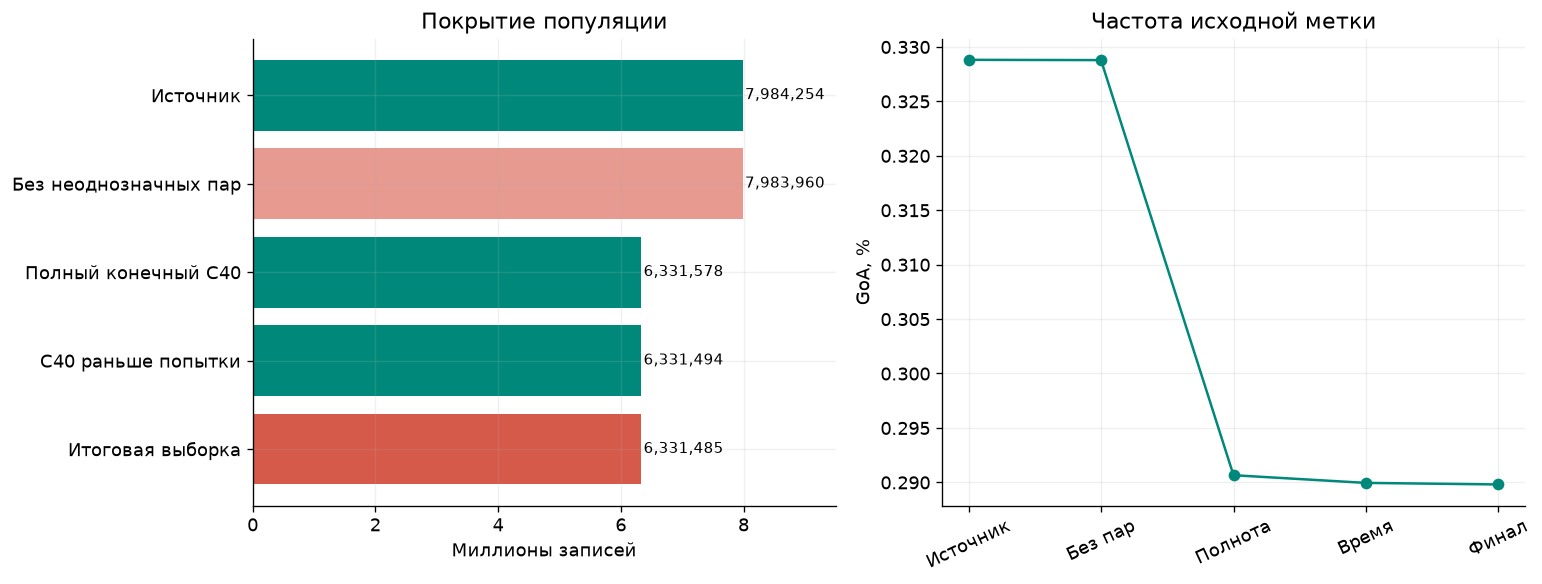

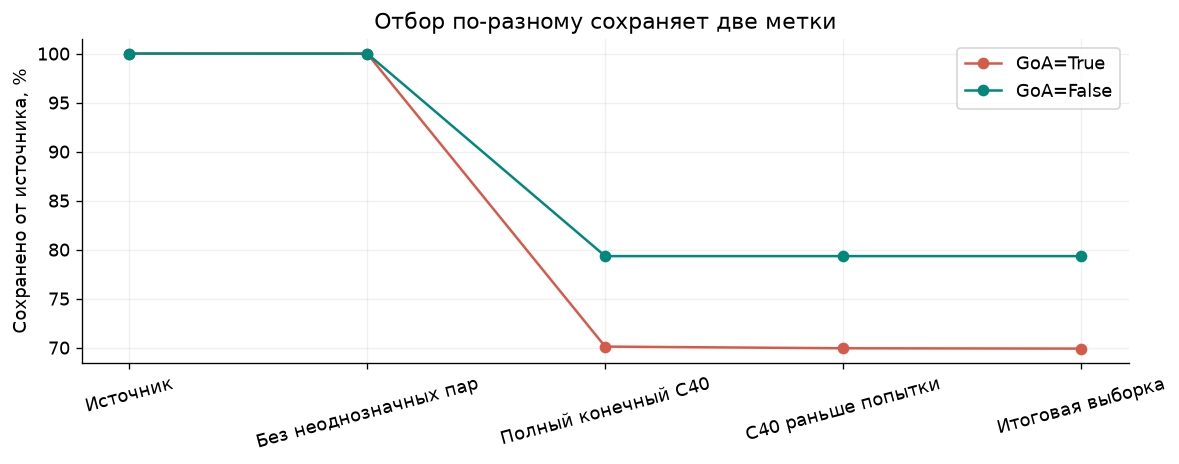

In [4]:
summary = pd.DataFrame([{'stage': s, 'rows': totals[s], 'goa': positives[s]} for s in STAGES])
summary['goa_pct'] = 100 * summary.goa / summary.rows
summary['retained_pct'] = 100 * summary.rows / totals['source']
summary['positive_retained_pct'] = 100 * summary.goa / positives['source']
summary['negative_retained_pct'] = 100 * (summary.rows-summary.goa) / (totals['source']-positives['source'])
summary['rows_removed_transition'] = summary.rows.shift(1) - summary.rows
summary['goa_removed_transition'] = summary.goa.shift(1) - summary.goa
summary['delta_goa_pp_transition'] = summary.goa_pct.diff()
summary.to_csv(REPORTS / 'selection_summary.csv', index=False)
display(summary.style.format(precision=4))
reason_table = pd.DataFrame([{'reason': r, 'rows': n, 'goa': reason_ga[r]} for r,n in reasons.items()])
reason_table['goa_pct'] = 100 * reason_table.goa / reason_table.rows
reason_table.to_csv(REPORTS / 'exclusive_reasons.csv', index=False)
display(reason_table.sort_values('rows', ascending=False).style.format(precision=4))
pd.DataFrame([dict(pair=k[0], missing_c40=k[1], not_before=k[2], manual=k[3], rows=v)
              for k,v in overlap.items()]).to_csv(REPORTS / 'rule_overlap.csv', index=False)
fig, axes = plt.subplots(1, 2, figsize=(13,5))
axes[0].barh([LABELS[s] for s in STAGES], summary.rows / 1e6, color=COLORS)
axes[0].invert_yaxis(); axes[0].set_xlabel('Миллионы записей'); axes[0].set_title('Покрытие популяции')
for i,n in enumerate(summary.rows): axes[0].text(n/1e6+.04, i, f'{n:,}', va='center', fontsize=9)
axes[0].set_xlim(0,9.5)
axes[1].plot(range(5), summary.goa_pct, 'o-', color=COLORS[0])
axes[1].set_xticks(range(5), ['Источник','Без пар','Полнота','Время','Финал'], rotation=25)
axes[1].set_ylabel('GoA, %'); axes[1].set_title('Частота исходной метки')
savefig('01_population_flow')
plt.figure(figsize=(10,4))
plt.plot([LABELS[s] for s in STAGES], summary.positive_retained_pct, 'o-', label='GoA=True', color='#D65A4A')
plt.plot([LABELS[s] for s in STAGES], summary.negative_retained_pct, 'o-', label='GoA=False', color='#00897B')
plt.xticks(rotation=15); plt.ylabel('Сохранено от источника, %'); plt.legend()
plt.title('Отбор по-разному сохраняет две метки'); savefig('02_label_retention')

## 5. Группы: покрытие, доля GoA и изменение состава

Доля группы в массиве позволяет отличить изменение ее веса от изменения частоты
метки внутри группы. Нулевые знаменатели дают NaN. Для небольших групп сохраняем
объемы, избегая выводов по одному проценту.

,rows_source,goa_source,composition_pct_source,rows_final,goa_final,composition_pct_final,rows_outside,goa_outside,retained_pct,positive_retained_pct,negative_retained_pct,goa_source_pct,goa_final_pct,goa_outside_pct,delta_goa_pp,composition_delta_pp
year,,,,,,,,,,,,,,,,
2019,2516384,7235,31.517,2172291,5973,34.309,344093,1262,86.326,82.557,86.337,0.288,0.275,0.367,-0.013,2.793
2020,1109554,4105,13.897,923609,2845,14.588,185945,1260,83.241,69.306,83.293,0.370,0.308,0.678,-0.062,0.691
2021,1368238,4637,17.137,1069160,2808,16.886,299078,1829,78.141,60.556,78.201,0.339,0.263,0.612,-0.076,-0.250
2022,2197853,7466,27.527,1619847,4984,25.584,578006,2482,73.701,66.756,73.725,0.340,0.308,0.429,-0.032,-1.943
2023,792225,2810,9.922,546578,1739,8.633,245647,1071,68.993,61.886,69.018,0.355,0.318,0.436,-0.037,-1.290


,rows_source,goa_source,composition_pct_source,rows_final,goa_final,composition_pct_final,rows_outside,goa_outside,retained_pct,positive_retained_pct,negative_retained_pct,goa_source_pct,goa_final_pct,goa_outside_pct,delta_goa_pp,composition_delta_pp
airport,,,,,,,,,,,,,,,,
LFPG,701670,2653,8.788,617562.000,2346.000,9.754,84108.000,307.000,88.013,88.428,88.012,0.378,0.380,0.365,0.002,0.966
EGLL,686819,2607,8.602,631718.000,2400.000,9.977,55101.000,207.000,91.977,92.060,91.977,0.380,0.380,0.376,0.000,1.375
EDDF,644881,2161,8.077,604960.000,1884.000,9.555,39921.000,277.000,93.810,87.182,93.832,0.335,0.311,0.694,-0.024,1.478
EHAM,639766,1414,8.013,561481.000,1038.000,8.868,78285.000,376.000,87.763,73.409,87.795,0.221,0.185,0.480,-0.036,0.855
LEMD,592140,1257,7.416,515044.000,986.000,8.135,77096.000,271.000,86.980,78.441,86.998,0.212,0.191,0.352,-0.021,0.718
EDDM,499206,1532,6.252,443203.000,1293.000,7.000,56003.000,239.000,88.782,84.399,88.795,0.307,0.292,0.427,-0.015,0.748
LIRF,391269,672,4.901,322749.000,466.000,5.098,68520.000,206.000,82.488,69.345,82.510,0.172,0.144,0.301,-0.027,0.197
LTFJ,387368,2414,4.852,0.000,0.000,0.000,387368.000,2414.000,0.000,0.000,0.000,0.623,nan,0.623,nan,-4.852
LSZH,372304,1486,4.663,316973.000,1144.000,5.006,55331.000,342.000,85.138,76.985,85.171,0.399,0.361,0.618,-0.038,0.343


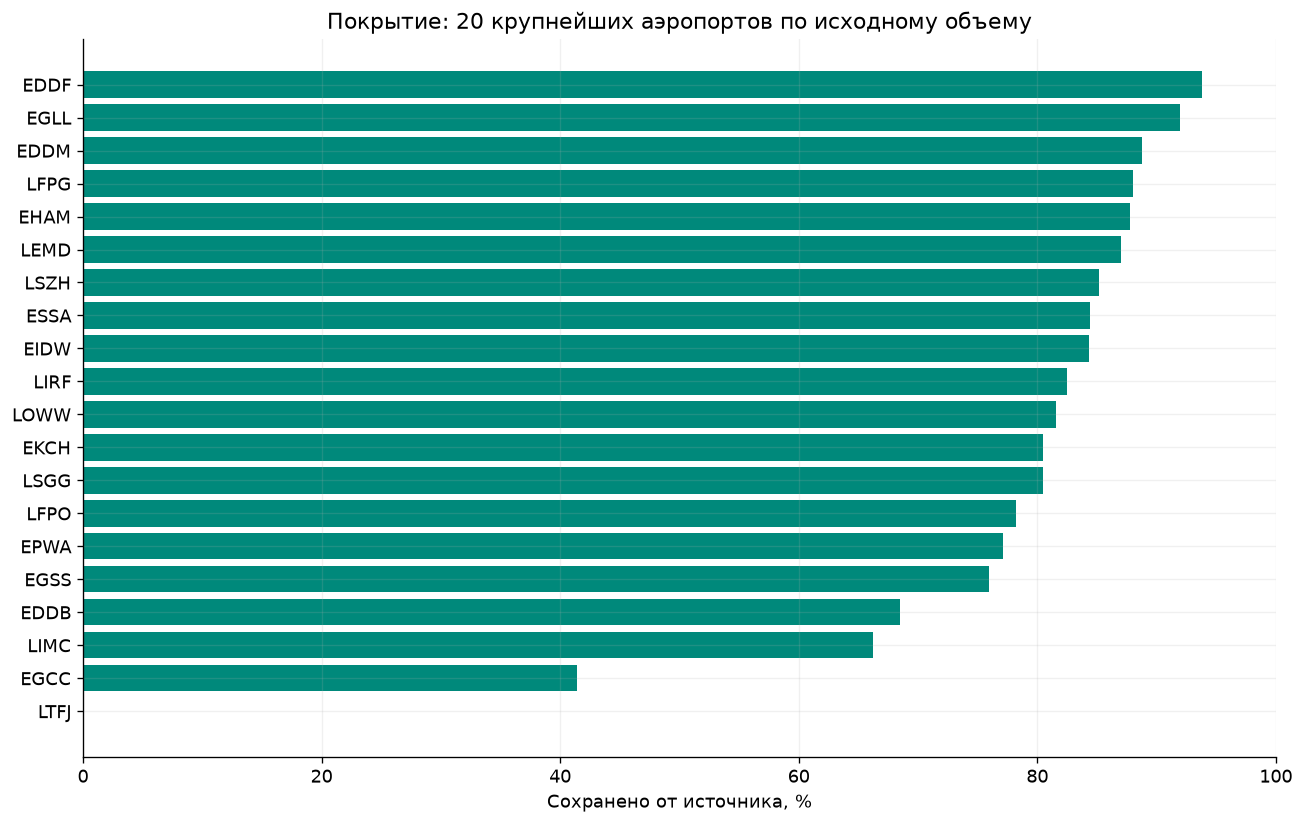

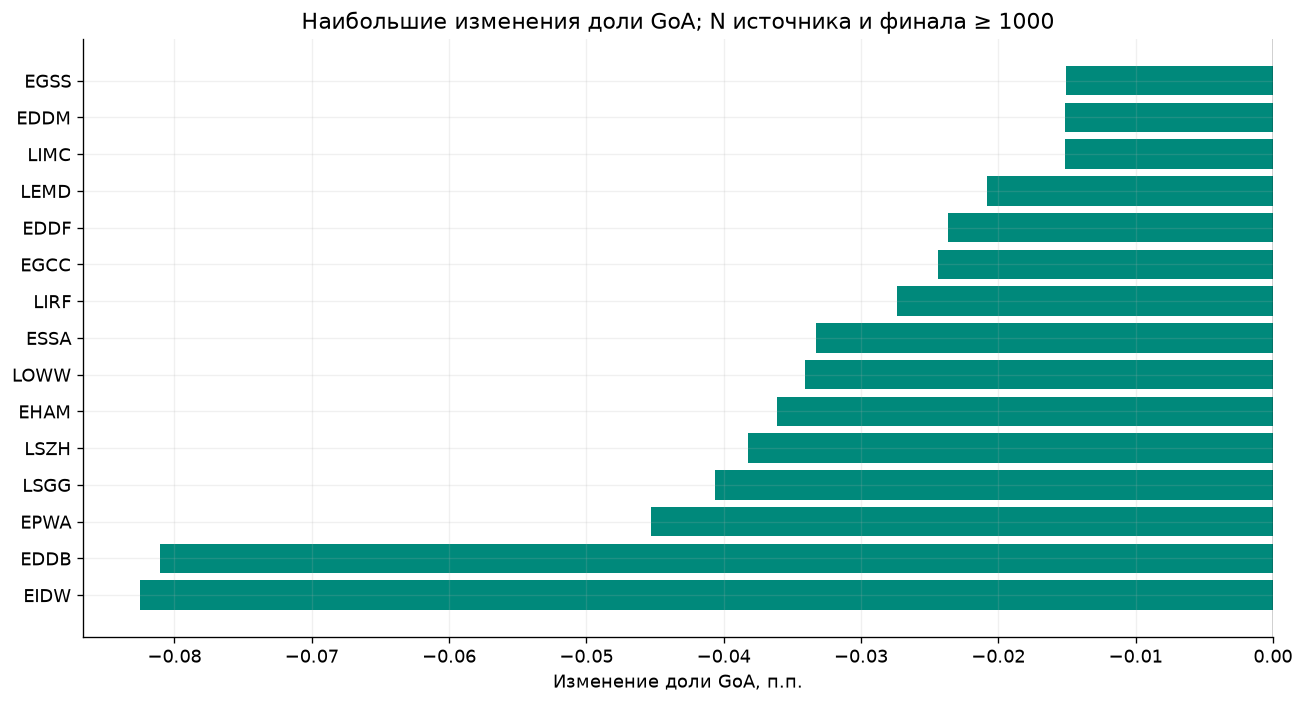

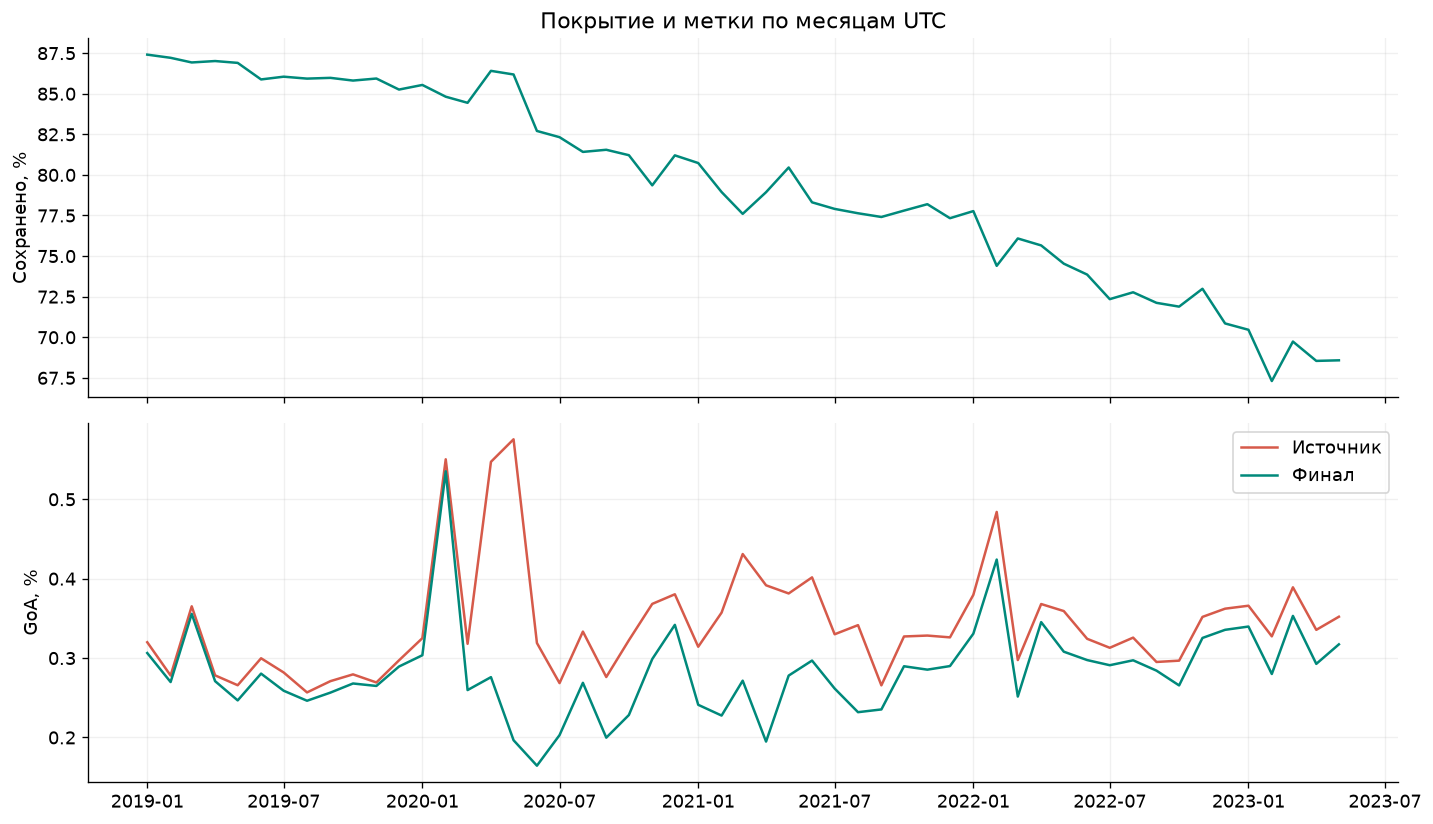

,rows_source,goa_source,composition_pct_source,rows_final,goa_final,composition_pct_final,rows_outside,goa_outside,retained_pct,positive_retained_pct,negative_retained_pct,goa_source_pct,goa_final_pct,goa_outside_pct,delta_goa_pp,composition_delta_pp
typecode,,,,,,,,,,,,,,,,
A320,1350700,4274,16.917,1269030.000,3908.000,20.043,81670.000,366.000,93.954,91.437,93.961,0.316,0.308,0.448,-0.008,3.126
[пропуск],1334092,4813,16.709,221671.000,701.000,3.501,1112421.000,4112.000,16.616,14.565,16.623,0.361,0.316,0.370,-0.045,-13.208
B738,1170953,4050,14.666,967666.000,2819.000,15.283,203287.000,1231.000,82.639,69.605,82.684,0.346,0.291,0.606,-0.055,0.618
A319,618064,1668,7.741,605033.000,1604.000,9.556,13031.000,64.000,97.892,96.163,97.896,0.270,0.265,0.491,-0.005,1.815
A321,429034,1584,5.374,420030.000,1531.000,6.634,9004.000,53.000,97.901,96.654,97.906,0.369,0.364,0.589,-0.005,1.260
A20N,338285,1096,4.237,272272.000,733.000,4.300,66013.000,363.000,80.486,66.880,80.530,0.324,0.269,0.550,-0.055,0.063
E190,187962,481,2.354,183945.000,462.000,2.905,4017.000,19.000,97.863,96.050,97.868,0.256,0.251,0.473,-0.005,0.551
E195,185683,444,2.326,183216.000,436.000,2.894,2467.000,8.000,98.671,98.198,98.673,0.239,0.238,0.324,-0.001,0.568
B77W,176380,667,2.209,169748.000,637.000,2.681,6632.000,30.000,96.240,95.502,96.243,0.378,0.375,0.452,-0.003,0.472


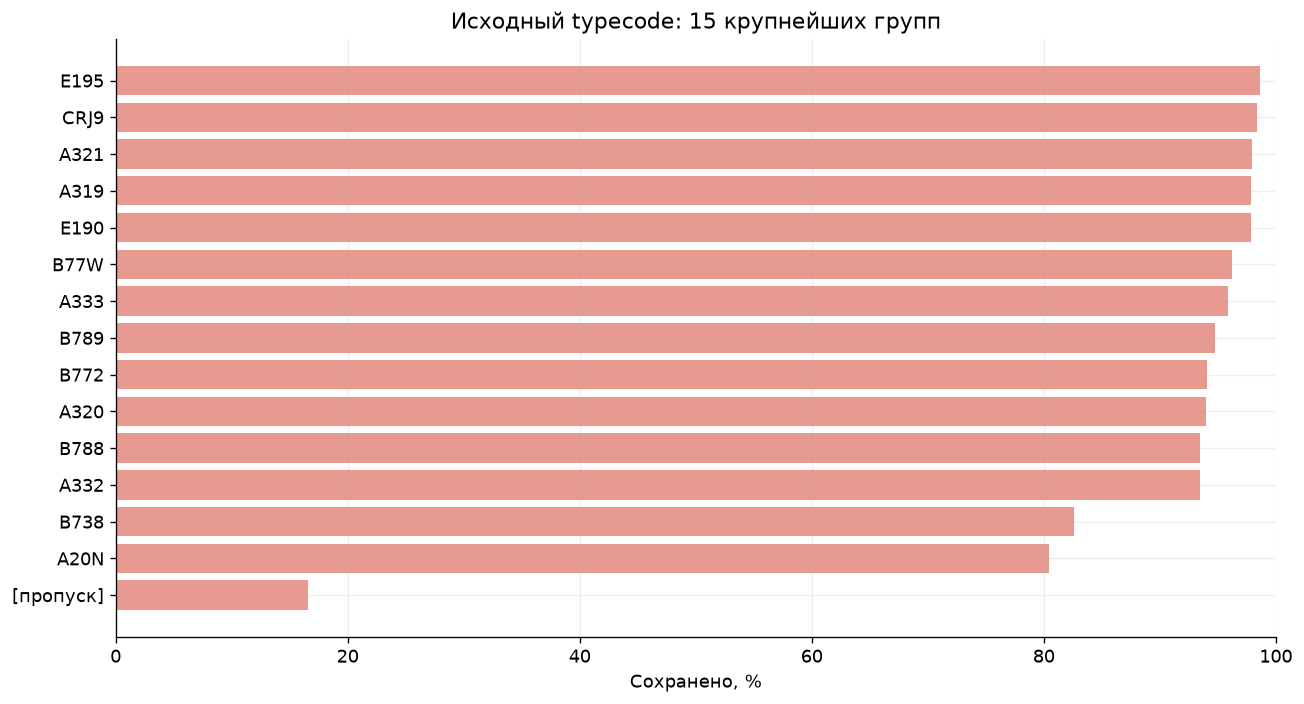

In [5]:
group_tables = {}; comparisons = {}
for g, chunks in parts.items():
    a = pd.concat(chunks).groupby([g,'stage'], dropna=False)[['rows','goa']].sum().reset_index()
    a['goa_pct'] = 100 * a.goa / a.rows
    a['composition_pct'] = 100 * a.rows / a.stage.map(totals)
    a.to_csv(REPORTS / f'by_{g}_all_stages.csv', index=False); group_tables[g] = a
    source = a[a.stage=='source'].set_index(g)[['rows','goa','composition_pct']].add_suffix('_source')
    final = a[a.stage=='final'].set_index(g)[['rows','goa','composition_pct']].add_suffix('_final')
    c = source.join(final, how='left')
    c[['rows_final','goa_final','composition_pct_final']] = c[['rows_final','goa_final','composition_pct_final']].fillna(0)
    c['rows_outside'] = c.rows_source-c.rows_final; c['goa_outside'] = c.goa_source-c.goa_final
    c['retained_pct'] = 100*c.rows_final/c.rows_source
    c['positive_retained_pct'] = 100*c.goa_final/c.goa_source.replace(0,np.nan)
    c['negative_retained_pct'] = 100*(c.rows_final-c.goa_final)/(c.rows_source-c.goa_source).replace(0,np.nan)
    c['goa_source_pct'] = 100*c.goa_source/c.rows_source
    c['goa_final_pct'] = 100*c.goa_final/c.rows_final.replace(0,np.nan)
    c['goa_outside_pct'] = 100*c.goa_outside/c.rows_outside.replace(0,np.nan)
    c['delta_goa_pp'] = c.goa_final_pct-c.goa_source_pct
    c['composition_delta_pp'] = c.composition_pct_final-c.composition_pct_source
    c.to_csv(REPORTS / f'comparison_{g}.csv'); comparisons[g] = c
display(comparisons['year'].style.format(precision=3))
airport = comparisons['airport'].sort_values('rows_source', ascending=False)
display(airport.head(15).style.format(precision=3))
top = airport.head(20).sort_values('retained_pct')
plt.figure(figsize=(11,7)); plt.barh(top.index,top.retained_pct,color=COLORS[2])
plt.xlabel('Сохранено от источника, %'); plt.xlim(0,100)
plt.title('Покрытие: 20 крупнейших аэропортов по исходному объему'); savefig('03_airport_coverage')
eligible = airport[(airport.rows_source>=1000)&(airport.rows_final>=1000)]
shifts = eligible.loc[eligible.delta_goa_pp.abs().nlargest(15).index].sort_values('delta_goa_pp')
plt.figure(figsize=(11,6)); plt.barh(shifts.index,shifts.delta_goa_pp,
    color=np.where(shifts.delta_goa_pp<0, COLORS[0], COLORS[4]))
plt.axvline(0,color='black',lw=.8); plt.xlabel('Изменение доли GoA, п.п.')
plt.title('Наибольшие изменения доли GoA; N источника и финала ≥ 1000'); savefig('04_airport_label_shift')
monthly = comparisons['month'].sort_index()
fig,axes = plt.subplots(2,1,figsize=(12,7),sharex=True)
x = pd.to_datetime(monthly.index)
axes[0].plot(x,monthly.retained_pct,color=COLORS[2]); axes[0].set_ylabel('Сохранено, %')
axes[1].plot(x,monthly.goa_source_pct,label='Источник',color='#D65A4A')
axes[1].plot(x,monthly.goa_final_pct,label='Финал',color='#00897B')
axes[1].set_ylabel('GoA, %'); axes[1].legend(); axes[0].set_title('Покрытие и метки по месяцам UTC')
savefig('05_monthly_selection')
types = comparisons['typecode'].sort_values('rows_source',ascending=False)
display(types.head(15).style.format(precision=3))
toptypes = types.head(15).sort_values('retained_pct')
plt.figure(figsize=(11,6)); plt.barh(toptypes.index,toptypes.retained_pct,color=COLORS[1])
plt.xlim(0,100); plt.xlabel('Сохранено, %'); plt.title('Исходный typecode: 15 крупнейших групп')
savefig('06_source_type_coverage')

## 6. Выводы и область применимости

Отличие состава описывает доступные данные. Оно не доказывает причинный механизм
пропусков, ошибочность исходных меток или ухудшение качества будущей модели.
Эксплуатационные исходы независимо не подтверждены. Наблюдения связаны по бортам,
датам и аэропортам. Отбор использует время будущей попытки как аудиторский критерий;
этот критерий нельзя автоматически считать доступным при реальном прогнозе.

In [6]:
s = summary.iloc[0]; t = summary.iloc[-1]
outside_n = int(s.rows-t.rows); outside_ga = int(s.goa-t.goa)
text = f"""### Результат полного пересчета

- Источник: **{int(s.rows):,}** записей, **{int(s.goa):,}** GoA ({s.goa_pct:.4f}%).
- Финал: **{int(t.rows):,}** записей, **{int(t.goa):,}** GoA ({t.goa_pct:.4f}%).
- Сохранено **{t.retained_pct:.2f}%** записей; GoA=True – **{t.positive_retained_pct:.2f}%**,
  GoA=False – **{t.negative_retained_pct:.2f}%**.
- Изменение частоты метки: **{t.goa_pct-s.goa_pct:+.4f} п.п.**
  (относительно исходной доли: **{100*(t.goa_pct/s.goa_pct-1):+.2f}%**).
- Не вошли **{outside_n:,}** записей с **{outside_ga:,}** GoA
  ({100*outside_ga/outside_n:.4f}%).

Для будущей модели нужно явно ограничить область применения наблюдениями
с пригодным C40. Сильнейшие различия групп требуют предметного разбора;
автоматически возвращать записи или назначать веса по этим результатам нельзя.
Материал дает количественную основу эксперимента A. Решение о статье требует
литературного обзора и оценки самостоятельности результата.
"""
display(Markdown(text))
(REPORTS / 'findings.md').write_text(text,encoding='utf-8')
environment = {'python':sys.version, 'platform':platform.platform(),
 'packages': {name:importlib.metadata.version(name) for name in
              ['numpy','pandas','pyarrow','matplotlib','nbformat','nbclient']}}
(REPORTS/'environment.json').write_text(json.dumps(environment,ensure_ascii=False,indent=2),encoding='utf-8')
(REPORTS/'verification.json').write_text(json.dumps({'inputs':manifest,'ordered_checks':verified,
 'pair_matches':removed_pair_count,'manual_matches':removed_manual_count,
 'verified_fields':STABLE,'all_source_columns_verified':False,
 'global_key_uniqueness_established':False},ensure_ascii=False,indent=2),encoding='utf-8')
print('Таблицы:', REPORTS, '\nРисунки:', FIGURES)

### Результат полного пересчета

- Источник: **7,984,254** записей, **26,253** GoA (0.3288%).
- Финал: **6,331,485** записей, **18,349** GoA (0.2898%).
- Сохранено **79.30%** записей; GoA=True – **69.89%**,
  GoA=False – **79.33%**.
- Изменение частоты метки: **-0.0390 п.п.**
  (относительно исходной доли: **-11.86%**).
- Не вошли **1,652,769** записей с **7,904** GoA
  (0.4782%).

Для будущей модели нужно явно ограничить область применения наблюдениями
с пригодным C40. Сильнейшие различия групп требуют предметного разбора;
автоматически возвращать записи или назначать веса по этим результатам нельзя.
Материал дает количественную основу эксперимента A. Решение о статье требует
литературного обзора и оценки самостоятельности результата.


Таблицы: D:\AI-ML Engineering\Projects\5 - Approach Risk ML\Approach Risk\research\sample-selection\reports 
Рисунки: D:\AI-ML Engineering\Projects\5 - Approach Risk ML\Approach Risk\research\sample-selection\figures
